# 04 · Reference data, fundamentals, short data and news

Everything that is not a price comes from Massive's REST API and is refreshed by the daily
sync. Each dataset has a name (see `store.datasets()`) and can be read with
`store.dataset(name, tickers, start, end)`; the common ones have shortcuts.

1. reference: tickers, identifiers, splits, dividends, IPOs
2. financial statements, point-in-time
3. ratios and float
4. short interest and short volume
5. news and sentiment

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from massive_subspace_stream import Store
from subspace_probe import style

style()
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
pl.Config.set_fmt_str_lengths(50)
store = Store()

## 1 · Reference data

### Tickers and identifiers
`store.tickers()` holds every stock ticker Massive knows, active and delisted, with
`composite_figi` and `cik` as stable issuer identifiers.

In [2]:
tickers = store.tickers()
print(f"{tickers.height:,} ticker records, {tickers.filter('active').height:,} active")
tickers.filter(pl.col("name").str.contains("(?i)nvidia|tesla|berkshire")).select(
    "ticker", "name", "type", "primary_exchange", "active", "cik", "composite_figi")

36,841 ticker records, 13,252 active


ticker,name,type,primary_exchange,active,cik,composite_figi
str,str,str,str,bool,str,str
"""BDVG""","""IMGP Berkshire Dividend Growth ETF""","""ETF""","""ARCX""",true,"""0001020425""","""BBG01H8T9X70"""
"""BERK""","""BERKSHIRE BANCORP INC""",null,null,false,null,"""BBG000BX8QJ8"""
"""BERK.D""","""BERKSHIRE BANCORP INC""",null,null,false,null,"""BBG000BX8QJ8"""
"""BGRY""","""Berkshire Grey, Inc. Class A Common Stock""","""CS""","""XNAS""",false,"""0001824734""","""BBG00Z3XYSD3"""
"""BGRYW""","""Berkshire Grey, Inc. Warrant""","""WARRANT""","""XNAS""",false,"""0001824734""","""BBG00Z48XPQ0"""
"""BHLB""","""Berkshire Hills Bancorp, Inc.""","""CS""","""XNYS""",false,"""0001108134""","""BBG000BB00D7"""
"""BIR.PRAC""","""BERKSHIRE INCM REALTY INC 9% SR A PFD""","""PFD""","""XASE""",false,null,null
"""BIRpA""","""BERKSHIRE INCM REALTY INC 9% SR A PFD""","""PFD""","""XASE""",false,null,null
"""BRK.A""","""Berkshire Hathaway Inc.""","""CS""","""XNYS""",true,"""0001067983""","""BBG000DWCFL4"""


**Symbols get reused.** `FB` was Facebook until 2022 (now `META`); today the symbol belongs to
an ETF. The day bars for `FB` in 2015 are still Facebook's, because bars are stored by symbol
as traded at the time. Join on `composite_figi` or `cik` when identity matters.

In [3]:
print(tickers.filter(pl.col("ticker").is_in(["FB", "META"])).select("ticker", "name", "active", "composite_figi"))
store.bars("FB", start="2015-01-02", end="2015-01-06").select("ticker", "date", "close", "volume")

shape: (2, 4)
┌────────┬───────────────────────────────────────────┬────────┬────────────────┐
│ ticker ┆ name                                      ┆ active ┆ composite_figi │
│ ---    ┆ ---                                       ┆ ---    ┆ ---            │
│ str    ┆ str                                       ┆ bool   ┆ str            │
╞════════╪═══════════════════════════════════════════╪════════╪════════════════╡
│ FB     ┆ ProShares S&P 500 Dynamic Buffer ETF      ┆ true   ┆ BBG01VRMNFB1   │
│ META   ┆ Meta Platforms, Inc. Class A Common Stock ┆ true   ┆ BBG000MM2P62   │
└────────┴───────────────────────────────────────────┴────────┴────────────────┘


ticker,date,close,volume
str,date,f64,f64
"""FB""",2015-01-02,78.45,1.8169239e7
"""FB""",2015-01-05,77.19,2.6005599e7
"""FB""",2015-01-06,76.15,2.7390724e7


### Splits
Reverse splits (several shares merged into one, usually to keep a falling stock above \$1 to
stay listed) have outnumbered forward splits every year since 2009:

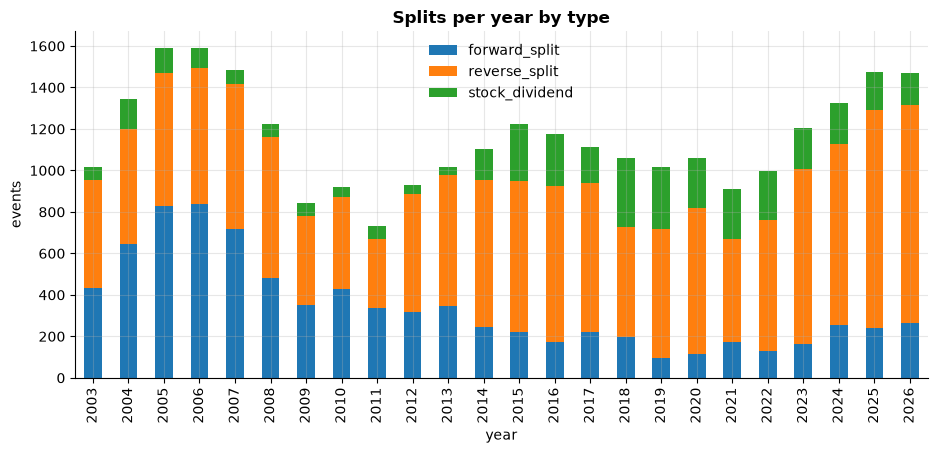

In [4]:
splits = store.splits()
by_year = (
    splits.group_by(pl.col("execution_date").dt.year().alias("year"), "adjustment_type")
    .agg(pl.len().alias("n"))
    .pivot(on="adjustment_type", index="year", values="n")
    .sort("year")
    .filter(pl.col("year").is_between(2003, 2026))
)
ax = by_year.to_pandas().set_index("year").plot.bar(stacked=True, title="Splits per year by type")
ax.set_ylabel("events");

### Dividends
AAPL's recent dividends. `historical_adjustment_factor` is the cumulative factor that
`adjust="all"` uses to build total-return prices.

In [5]:
store.dividends("AAPL").sort("ex_dividend_date").tail(6).select(
    "ex_dividend_date", "pay_date", "cash_amount", "frequency", "distribution_type", "historical_adjustment_factor")

ex_dividend_date,pay_date,cash_amount,frequency,distribution_type,historical_adjustment_factor
date,date,f64,i64,str,f64
2025-05-12,2025-05-15,0.26,4,"""recurring""",0.993887
2025-08-11,2025-08-14,0.26,4,"""recurring""",0.99519
2025-11-10,2025-11-13,0.26,4,"""recurring""",0.99632
2026-02-09,2026-02-12,0.26,4,"""recurring""",0.997285
2026-05-11,2026-05-14,0.27,4,"""recurring""",0.998219
2026-08-10,2026-08-13,0.27,4,"""recurring""",0.999138


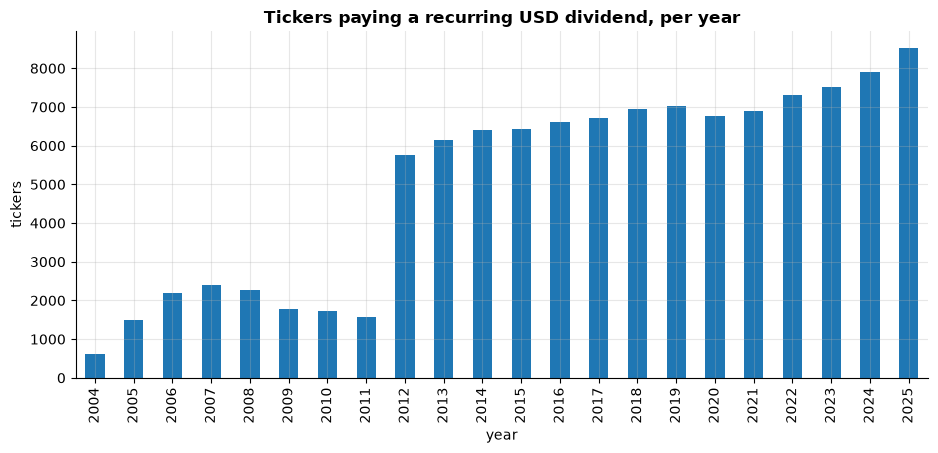

In [6]:
payers = (
    store.dividends()
    .filter(pl.col("currency") == "USD", pl.col("distribution_type") == "recurring")
    .group_by(pl.col("ex_dividend_date").dt.year().alias("year"))
    .agg(pl.col("ticker").n_unique().alias("tickers_paying"), pl.len().alias("payments"))
    .filter(pl.col("year").is_between(2004, 2025))
    .sort("year")
)
ax = payers.to_pandas().set_index("year")["tickers_paying"].plot.bar(title="Tickers paying a recurring USD dividend, per year")
ax.set_ylabel("tickers");

**Coverage check.** The jump in 2012 is a change in Massive's coverage, not in the market.
Large payers have complete histories back to 2003, but coverage of smaller names before 2012
is patchy. Before trusting `adjust="all"` for an old small-cap, check its dividends:

In [7]:
paid_2013 = set(store.dividends().filter(pl.col("ex_dividend_date").dt.year() == 2013)["ticker"])
paid_2010 = set(store.dividends().filter(pl.col("ex_dividend_date").dt.year() == 2010)["ticker"])
traded_2010 = set(store.universe("2010-06-30", types=["CS"])["ticker"])
cohort = paid_2013 & traded_2010
print(f"common stocks trading in 2010 that paid in 2013: {len(cohort):,}; "
      f"of these, {len(cohort - paid_2010):,} ({len(cohort - paid_2010) / len(cohort):.0%}) have no 2010 dividend on record")
store.dividends(["KO", "XOM", "PG", "JNJ"]).group_by("ticker").agg(
    pl.col("ex_dividend_date").min().alias("first_dividend"), pl.len().alias("payments")).sort("ticker")

common stocks trading in 2010 that paid in 2013: 1,603; of these, 240 (15%) have no 2010 dividend on record


ticker,first_dividend,payments
str,date,u32
"""JNJ""",2004-02-12,92
"""KO""",2003-06-11,95
"""PG""",2003-04-15,95
"""XOM""",2004-02-09,91


### IPOs
Completed listings per year. The 2020–2021 boom stands out, much of it in the `SP` category,
which matches the SPAC wave.

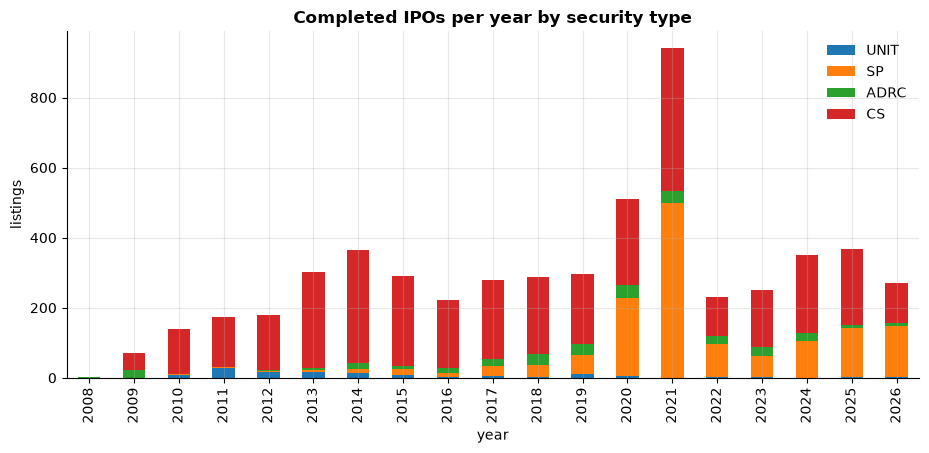

In [8]:
ipos = store.dataset("ipos").filter(pl.col("ipo_status") == "history", pl.col("listing_date").is_not_null())
per_year = ipos.group_by(pl.col("listing_date").dt.year().alias("year"), "security_type").agg(pl.len().alias("n")).filter(pl.col("year") >= 2008)
top_types = per_year.group_by("security_type").agg(pl.col("n").sum()).sort("n", descending=True).head(4)["security_type"].to_list()
ax = (
    per_year.with_columns(pl.when(pl.col("security_type").is_in(top_types)).then("security_type").otherwise(pl.lit("other")).alias("type"))
    .group_by("year", "type").agg(pl.col("n").sum())
    .pivot(on="type", index="year", values="n").sort("year").to_pandas().set_index("year")
    .plot.bar(stacked=True, title="Completed IPOs per year by security type")
)
ax.set_ylabel("listings");

## 2 · Financial statements and the point-in-time problem

Income statements, balance sheets and cash flow statements from SEC filings since 2010, as
`quarterly`, `annual` and `trailing_twelve_months` rows. Rows have a list of `tickers` (one
filer can have several share classes) and a `cik`.

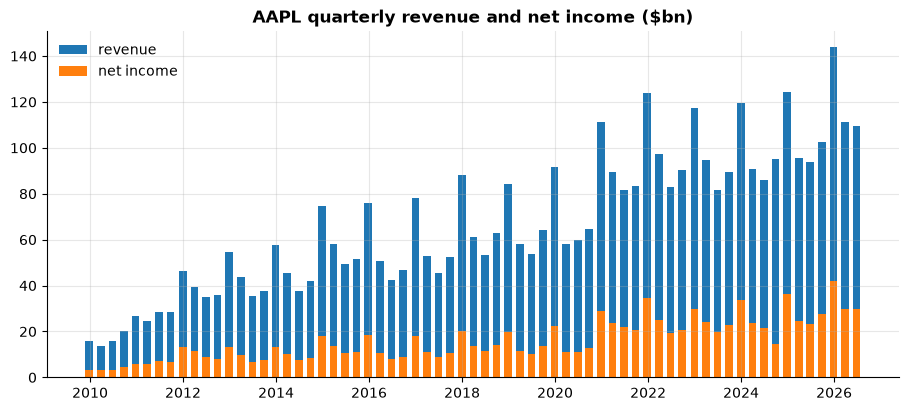

In [9]:
inc = store.financials("income", tickers="AAPL").filter(pl.col("timeframe") == "quarterly").sort("period_end")
fig, ax = plt.subplots()
x = inc["period_end"].to_list()
ax.bar(x, inc["revenue"] / 1e9, width=60, label="revenue")
ax.bar(x, inc["net_income_loss_attributable_common_shareholders"] / 1e9, width=60, label="net income")
ax.set_title("AAPL quarterly revenue and net income ($bn)")
ax.legend();

Two dates matter for a backtest: `period_end` (the end of the fiscal period) and the date the
numbers became public. A strategy may only use numbers after they were published.

**Caveat:** Massive keeps **one row per fiscal period**, and its `filing_date` is the *latest*
filing that reported that period. Companies repeat last year's quarter in this year's report
for comparison, so most rows carry a filing date about a year after the original report.
AAPL's recent quarters:

In [10]:
inc.tail(8).select("period_end", "fiscal_year", "fiscal_quarter", "filing_date",
                   (pl.col("filing_date") - pl.col("period_end")).dt.total_days().alias("days_after_period_end"))

period_end,fiscal_year,fiscal_quarter,filing_date,days_after_period_end
date,i64,i64,date,i64
2024-09-28,2024,4,2025-10-31,398
2024-12-28,2025,1,2026-01-30,398
2025-03-29,2025,2,2026-05-01,398
2025-06-28,2025,3,2026-07-31,398
2025-09-27,2025,4,2025-10-31,34
2025-12-27,2026,1,2026-01-30,34
2026-03-28,2026,2,2026-05-01,34
2026-06-27,2026,3,2026-07-31,34


Only the most recent quarters still show their original filing date (about 35 days after the
quarter ended). Across all companies the lag is two clusters: recent originals near 40 days,
and re-reported older periods near 400 days.

rows within 100 days of period end: 14%


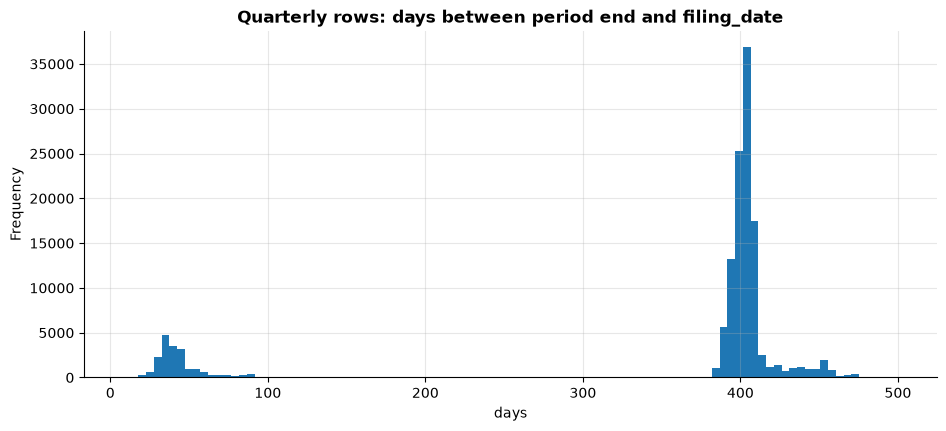

In [11]:
lag = (
    store.scan("income_statements")
    .filter(pl.col("timeframe") == "quarterly", pl.col("period_end") >= pl.date(2015, 1, 1))
    .select((pl.col("filing_date") - pl.col("period_end")).dt.total_days().alias("days"))
    .filter(pl.col("days").is_between(0, 500))
    .collect()
)
print(f"rows within 100 days of period end: {(lag['days'] < 100).mean():.0%}")
ax = lag.to_pandas()["days"].plot.hist(bins=100, title="Quarterly rows: days between period end and filing_date")
ax.set_xlabel("days");

What this means:
- Filtering on `filing_date` (what `store.financials(start=, end=)` does) **never looks ahead**,
  but it hides most periods for about a year, so as-of queries look stale.
- The values are the latest reported ones, which may include restatements that were not known
  at the original filing.
- The store keeps every version it downloads (`filing_date` is part of the key), so exact
  point-in-time history builds up from the first download (2026-10-31) onward.

A practical approximation for backtests is an **estimated availability date**: period end
plus 45 days for quarterly reports (SEC deadlines are 40–45 days for 10-Qs and 60–90 days for
10-Ks). Exact original filing dates would need a second source such as SEC EDGAR.

In [12]:
def with_available_date(statements: pl.DataFrame) -> pl.DataFrame:
    """Earliest date the numbers can safely be assumed public."""
    est = pl.col("period_end") + pl.when(pl.col("timeframe") == "annual").then(pl.duration(days=90)).otherwise(pl.duration(days=45))
    return statements.with_columns(pl.min_horizontal(est, pl.col("filing_date")).alias("available_date"))


ttm = with_available_date(store.financials("income", tickers="AAPL")).filter(pl.col("timeframe") == "trailing_twelve_months")
as_of = pl.date(2024, 6, 30)
pl.concat([
    ttm.filter(pl.col("filing_date") <= as_of).sort("period_end").tail(1).with_columns(pl.lit("filter on filing_date").alias("method")),
    ttm.filter(pl.col("available_date") <= as_of).sort("period_end").tail(1).with_columns(pl.lit("filter on available_date").alias("method")),
]).select("method", "period_end", "filing_date", "available_date", (pl.col("revenue") / 1e9).round(1).alias("ttm_revenue_bn"))

method,period_end,filing_date,available_date,ttm_revenue_bn
str,date,date,date,f64
"""filter on filing_date""",2023-04-01,2024-05-03,2023-05-16,385.1
"""filter on available_date""",2024-03-30,2025-05-02,2024-05-14,381.6


On 2024-06-30, AAPL's March 2024 quarter had been public for two months; the estimated
availability date finds it, while the raw `filing_date` filter falls back to a year-old period.

## 3 · Ratios and float

`ratios` is a daily snapshot of valuation and quality ratios computed by Massive. The API only
serves the current values, so history builds up from each daily refresh; it starts in
October 2026 here.

In [13]:
ratios = store.dataset("ratios")
latest = ratios["date"].max()
print(f"ratios: {ratios['date'].n_unique()} days from {ratios['date'].min()} to {latest}, {ratios.filter(pl.col('date') == latest).height:,} tickers on the latest day")
ratios.filter(pl.col("date") == latest).sort("market_cap", descending=True, nulls_last=True).head(10).select(
    "ticker", (pl.col("market_cap") / 1e9).round(0).alias("mcap_bn"), "price_to_earnings", "price_to_book", "dividend_yield", "return_on_equity", "debt_to_equity")

ratios: 21 days from 2026-10-01 to 2026-10-30, 4,773 tickers on the latest day


ticker,mcap_bn,price_to_earnings,price_to_book,dividend_yield,return_on_equity,debt_to_equity
str,f64,f64,f64,f64,f64,f64
"""AAPL""",5030.0,39.01,46.78,0.0031,1.1991,0.78
"""NVDA""",4941.0,25.62,21.58,0.0014,0.8423,0.15
"""MSFT""",3876.0,27.17,8.24,0.007,0.3031,0.08
"""GOOGL""",3440.0,14.62,5.08,0.0031,0.3473,0.18
"""GOOG""",3420.0,14.54,5.05,0.0031,0.3473,0.18
"""AMZN""",2599.0,19.28,4.24,0.0,0.2197,0.28
"""META""",1601.0,21.27,5.88,0.0034,0.2763,0.3
"""TSLA""",1580.0,491.09,17.7,0.0,0.036,0.11
"""AVGO""",1557.0,40.68,15.61,0.0078,0.3838,0.6


free float: 6,976 tickers; median free float 87.7%


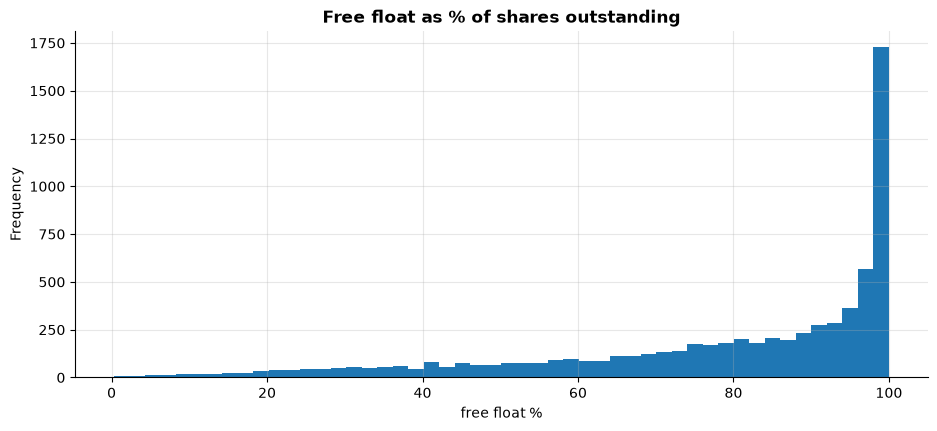

In [14]:
fl = store.dataset("float")
print(f"free float: {fl.height:,} tickers; median free float {fl['free_float_percent'].median():.1f}%")
ax = fl.to_pandas()["free_float_percent"].plot.hist(bins=50, title="Free float as % of shares outstanding")
ax.set_xlabel("free float %");

## 4 · Short interest and short volume

- **Short interest** (FINRA, twice a month since 2017): shares sold short and still open on the
  settlement date. `days_to_cover` = short interest / average daily volume.
- **Short volume** (daily, since 2024): the part of each day's off-exchange volume that was a
  short sale. Market makers sell short routinely to fill buy orders, so ratios around 40–60%
  are normal and are *not* the same as bearish positioning.

GameStop's January 2021 squeeze in short-interest data (raw prices and shares, both as of the
time, so they are consistent with each other; GME's 2022 split came later):

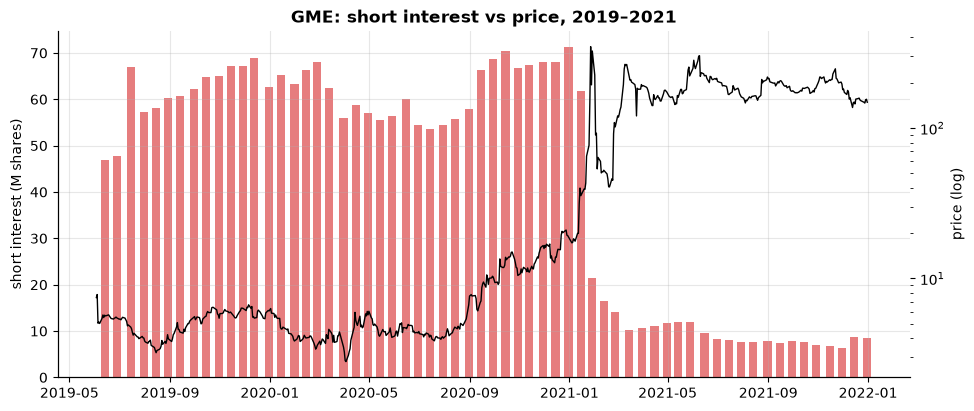

In [15]:
si = store.short_interest("GME", start="2019-06-01", end="2021-12-31")
px = store.bars("GME", start="2019-06-01", end="2021-12-31")
fig, ax = plt.subplots()
ax.bar(si["settlement_date"].to_list(), si["short_interest"] / 1e6, width=10, color="tab:red", alpha=0.6, label="short interest (M shares)")
ax.set_ylabel("short interest (M shares)")
ax2 = ax.twinx()
ax2.plot(px["date"].to_list(), px["close"].to_list(), color="black", lw=1, label="GME close (raw)")
ax2.set_yscale("log")
ax2.set_ylabel("price (log)")
ax2.grid(False)
ax.set_title("GME: short interest vs price, 2019–2021");

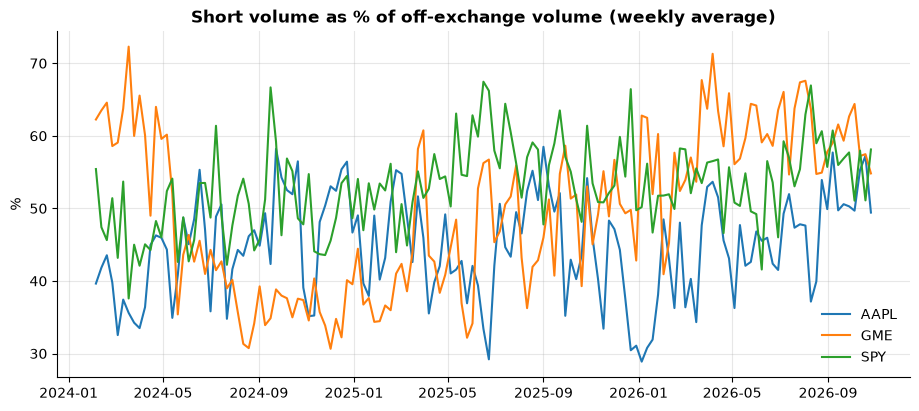

In [16]:
sv = store.short_volume(["SPY", "AAPL", "GME"], start="2024-01-01")
weekly = sv.group_by("ticker", pl.col("date").dt.truncate("1w").alias("week")).agg(pl.col("short_volume_ratio").mean()).sort("ticker", "week")
fig, ax = plt.subplots()
for (t,), g in weekly.group_by("ticker", maintain_order=True):
    ax.plot(g["week"].to_list(), g["short_volume_ratio"].to_list(), label=t)
ax.set_title("Short volume as % of off-exchange volume (weekly average)")
ax.set_ylabel("%")
ax.legend();

## 5 · News and sentiment

About 840,000 articles since 2016, each tagged with tickers and keywords. Since 2024 many
articles also carry `insights`: a per-ticker sentiment (positive / neutral / negative) with a
one-line reason.

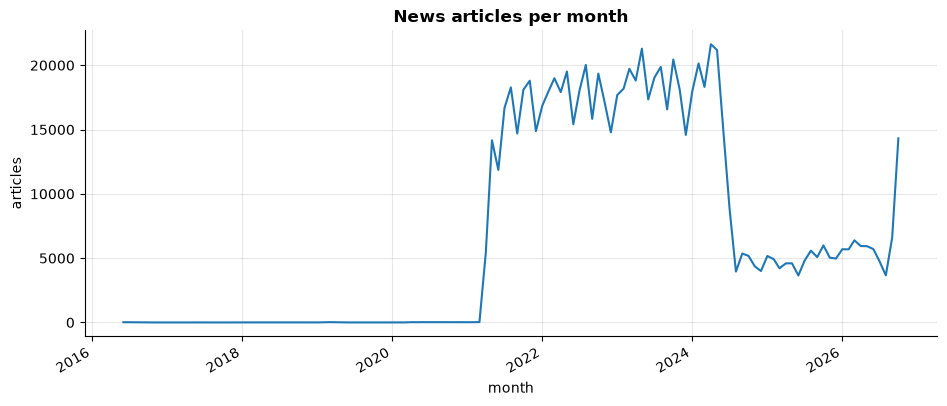

In [17]:
news = store.news()
monthly = news.group_by(pl.col("published_utc").dt.truncate("1mo").alias("month")).agg(pl.len().alias("articles")).sort("month")
ax = monthly.to_pandas().set_index("month")["articles"].plot(title="News articles per month")
ax.set_ylabel("articles");

Article counts reflect the **feed's coverage**, not how much news there was: almost nothing
before 2021, then publishers joining and leaving (the drop in 2024 is publishers leaving the
feed). Normalize by coverage (for example, share of articles per ticker) before using counts
as a signal.

In [18]:
news.group_by("publisher_name").agg(pl.len().alias("articles"), pl.col("published_utc").min().dt.date().alias("first"),
                                    pl.col("published_utc").max().dt.date().alias("last")).sort("articles", descending=True).head(10)

publisher_name,articles,first,last
str,u32,date,date
"""Zacks Investment Research""",313523,2020-03-27,2026-10-30
"""GlobeNewswire Inc.""",199951,2021-07-21,2026-10-31
"""The Motley Fool""",160814,2016-11-21,2026-10-31
"""Benzinga""",99034,2021-04-23,2026-06-18
"""MarketWatch""",27238,2021-04-23,2026-04-27
"""Seeking Alpha""",15673,2021-04-20,2024-07-02
"""Investing.com""",13750,2021-04-23,2026-07-16
"""Invezz""",2529,2021-04-21,2025-03-06
"""PennyStocks""",2484,2021-07-20,2024-07-02


In [19]:
last = news["published_utc"].max()
recent = news.filter(pl.col("published_utc") > last - pl.duration(days=30))
print(f"most-mentioned tickers in the 30 days to {last:%Y-%m-%d}:")
recent.explode("tickers").group_by(pl.col("tickers").alias("ticker")).agg(pl.len().alias("articles")).sort("articles", descending=True).head(12)

most-mentioned tickers in the 30 days to 2026-10-31:


ticker,articles
str,u32
"""NVDA""",710
"""GOOGN""",487
"""GOOGL""",487
"""GOOGM""",487
"""GOOG""",487
"""MSFT""",446
"""AMZN""",392
"""AAPL""",296
"""META""",291


In [20]:
insight_type = pl.List(pl.Struct({"ticker": pl.String, "sentiment": pl.String, "sentiment_reasoning": pl.String}))
sent = (
    news.filter(pl.col("insights").is_not_null())
    .with_columns(pl.col("insights").str.json_decode(insight_type))
    .explode("insights")
    .unnest("insights")
)
example = sent.filter(pl.col("ticker") == "NVDA").sort("published_utc").tail(3).select("published_utc", "title", "sentiment", "sentiment_reasoning")
example

published_utc,title,sentiment,sentiment_reasoning
"datetime[μs, UTC]",str,str,str
2026-10-31 12:45:01 UTC,"""Jensen Huang Just Announced Fantastic News for Nvi…","""positive""","""Soaring neocloud demand drives GPU purchases; medi…"
2026-10-31 13:06:01 UTC,"""4 Words From Fed Chair Kevin Warsh Should Have Wal…","""negative""","""AI hardware leader whose demand depends on continu…"
2026-10-31 14:45:00 UTC,"""Why SpaceX Stock Is Worth Buying and Holding for 1…","""positive""","""SpaceX's massive deployment of 200,000 Nvidia GB30…"


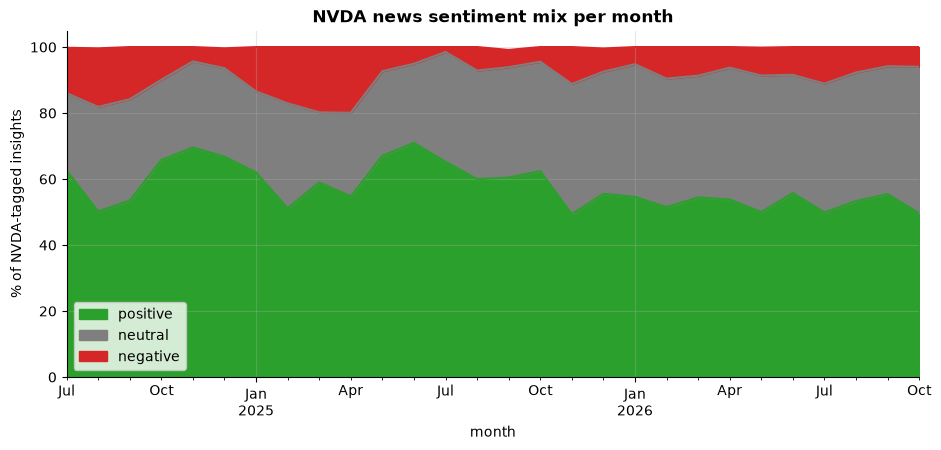

In [21]:
nvda = (
    sent.filter(pl.col("ticker") == "NVDA")
    .group_by(pl.col("published_utc").dt.truncate("1mo").alias("month"), "sentiment")
    .agg(pl.len().alias("n"))
    .pivot(on="sentiment", index="month", values="n")
    .fill_null(0)
    .sort("month")
    .to_pandas()
    .set_index("month")
)
share = nvda.div(nvda.sum(axis=1), axis=0) * 100
ax = share[[c for c in ("positive", "neutral", "negative") if c in share]].plot.area(
    color=["tab:green", "tab:gray", "tab:red"], title="NVDA news sentiment mix per month")
ax.set_ylabel("% of NVDA-tagged insights")
ax.legend(loc="lower left", frameon=True, facecolor="white");

## Takeaways
- Reference tables are snapshots: identify companies by `composite_figi` / `cik`, not symbol.
- Coverage changes over time (dividends before 2012, news before 2021): check before using a
  long history.
- Fundamentals carry the latest filing date per period; use an estimated availability date
  (or accumulated versions) for point-in-time backtests.
- Short volume ratio is not short interest; read the definitions before building signals.
- News `insights` give ready-made per-ticker sentiment since 2024.

Next: **05 · Real-time data**.